# Goemotions Data Exploration

320 Data Preprocessing & Basic Data Exploration

Group Members: Sienna, Samara, Micah, Nazia, Tyler

This notebook processes the Goemotions dataset and presents three statistical conclusions using hypothesis testing, correlation analysis, and comparative testing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', None)

df = pd.read_csv('goemotions.csv')

emotion_cols = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

df['created_utc'] = pd.to_datetime(df['created_utc'], unit='s')
df[emotion_cols] = df[emotion_cols].astype('int8')
df['text_length'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

display(df.head())
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Date range: {df['created_utc'].min().date()} to {df['created_utc'].max().date()}")
print(f"Unique comments: {df['id'].nunique()}")
print(f"Unique raters: {df['rater_id'].nunique()}")
print(f"Unique subreddits: {df['subreddit'].nunique()}")
print(f"Missing values: {df.isnull().sum().sum()}")

,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,disappointment,disapproval,disgust,embarrassment,excitement,fear,gratitude,grief,joy,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral,text_length,word_count
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,2019-01-25 01:50:39,1,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,15,3
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,2019-01-21 15:22:49,37,True,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,127,21
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,2019-01-02 11:15:44,37,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,46,10
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,2019-01-20 06:17:34,18,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,18,4
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,2019-01-05 06:10:01,2,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,52,10


Shape: 211225 rows, 39 columns
Date range: 2019-01-01 to 2019-01-31
Unique comments: 58011
Unique raters: 82
Unique subreddits: 483
Missing values: 0


## Conclusion 1: Chi-Square Test: Is emotion distribution independent of subreddit?

H0: The subreddit a comment comes from has no effect on whether the comment is labeled neutral or emotional.

HA: The subreddit a comment comes from does have an effect on whether the comment is labeled neutral or emotional.

We use a chi-squared test because both subreddit and whether a comment is neutral are categorical variables. The chi-squared test is specifically designed to test whether two categorical variables are independent.

is_neutral,False,True
subreddit,,
AnimalsBeingBros,633,194
OkCupid,604,213
cringe,666,229
loveafterlockup,645,225
socialanxiety,693,168


Chi-squared statistic: 14.387301326064854
P-value: 0.006156227437157415
Degrees of freedom: 4


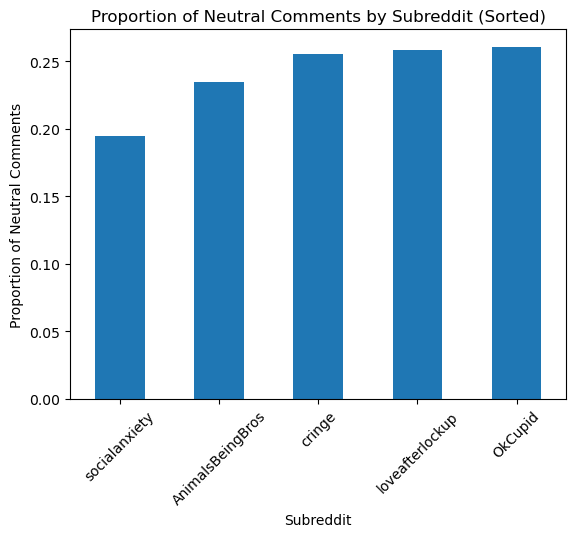

In [2]:
top_subreddits = df['subreddit'].value_counts().head(5).index
top_df = df[df['subreddit'].isin(top_subreddits)].copy()
top_df['is_neutral'] = top_df['neutral'] == 1

contingency_table = pd.crosstab(top_df['subreddit'], top_df['is_neutral'])
display(contingency_table)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-squared statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")

#Plot
neutral_props = top_df.groupby('subreddit')['is_neutral'].mean().sort_values()
neutral_props.plot(kind='bar')
plt.xlabel('Subreddit')
plt.ylabel('Proportion of Neutral Comments')
plt.title('Proportion of Neutral Comments by Subreddit (Sorted)')
plt.xticks(rotation=45)
plt.show()

Since the p < .05, we reject the null hypothesis, as there is statistical significant evidence that the subreddit a comment comes from influences whether it is labeled neutral or emotional The bar plot also shows the the proportion of neutral comments slightly varies across subreddits.